# Smog Album: The Wind That Sweeps the Smog

Issue #49. Follows [notebook-guide.md](../docs/notebook-guide.md) and [data-guide.md](../docs/data-guide.md). The album plays nell-v2's music (its loops) over four cities, heard through the air above each: the smog blows in from outside the map, covers the city and passes on, and the music is only muffled by it (user, 2026-11-15).

**What this notebook decides:** which four cities and which hours. What the user asked of them:

- the air flows in from outside the box that is looked at, covers the city and passes on, so the concentration over the city rises and falls gradually;
- no smog that sits still, and nothing that pops out of nowhere inside the box (a wildfire starting inside it, a plume bursting like a firework);
- time runs at one fixed speed, **3 hours of the data a second** (6 hours a bar), the same in every song; a song is as long as its hours, **at most 50 seconds (150 hours)**, and the songs differ by 2 to 5 seconds;
- only 2025 data, plus New York 2023 (the user asked for it).

**Why AOD, not PM2.5 (user, 2026-11-15):** PM2.5 at the surface, 5151's quantity, empties out of the whole box every morning as the day's heat mixes the air upward, and fills in again in place, so the smog seemed to blink out and back. The column's aerosol optical depth (AOD, the haze in the whole column of air) from the same model, on the same grid and hours, does not.

**Steps:**

1. EIC's message about PM2.5 (5151), the smog the album follows.
2. A worldwide screen of 2025 at a coarse grid, for events where smog enters a place from outside, covers it and leaves, with nothing popping up inside.
3. The four cities at the grid the app draws (0.25°, hourly): their hours picked by the same rules, checked on graphs and maps.
4. The four songs exported as tracks.

> The cities, the hours and the rules that pick them are **ours**. EIC 5151 shows the whole world's PM2.5 and names no place.

Run with `npm run notebook`. The first run reads about 33 × 33 cell boxes and a coarse worldwide year from NASA's OPeNDAP server (about 80 MB, 30 to 60 minutes) into `data/smog/raw/` and exports the tracks to `data/smog/tracks/`.

In [1]:
import html
import json
import re
import struct
import time
from concurrent.futures import ThreadPoolExecutor
from datetime import datetime, timedelta, timezone
from pathlib import Path
from zoneinfo import ZoneInfo

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from IPython.display import Markdown, display

pd.set_option("display.max_colwidth", 120)
plt.rcParams.update({"figure.dpi": 72, "axes.spines.top": False, "axes.spines.right": False})

RAW = Path("../data/smog/raw")
for sub in ("api", "screen_aod", "global6h", "natural_earth"):
    (RAW / sub).mkdir(parents=True, exist_ok=True)
TRACKS = Path("../data/smog/tracks")

# GEOS-CF v1, the hourly column collection, served by OPeNDAP so a box can be read alone. The aerosol optical depth at
# 550 nm is the sum of its six aerosols' (black and organic carbon, sulfate with nitrate and ammonium, dust, fine and
# coarse sea salt); its clouds' is left out.
OPENDAP = "https://opendap.nccs.nasa.gov/dods/gmao/geos-cf/assim/xgc_tavg_1hr_g1440x721_x1"
AOD_PARTS = ("aod550_bc", "aod550_oc", "aod550_sulfate", "aod550_dust", "aod550_sala", "aod550_salc")
AOD_DECIMALS = 3                           # as the tracks hold it
FIRST_HOUR = datetime(2018, 1, 1, 0, 30, tzinfo=timezone.utc)  # hourly means, stamped mid-hour
GRID_DEG = 0.25
LON_POINTS = 1440
BOX = 16                                   # cells each way from the city's cell: ±4°, 33 × 33 cells
HOURS_PER_REQUEST = 24                     # the server reads one file per hour
PARALLEL = 6
RETRIES = 5
TIMEOUT_SEC = 120

NATURAL_EARTH_50M = "https://naciscdn.org/naturalearth/50m/cultural"
CREDIT = "Source: GEOS-CF v1 (NASA GMAO), aerosol optical depth at 550 nm (sum of its six aerosols), hourly means"


def download(name, url):
    path = RAW / name
    if not path.exists():
        r = requests.get(url, timeout=TIMEOUT_SEC)
        r.raise_for_status()
        path.write_bytes(r.content)
    return path


def svs_page(page_id):
    path = RAW / "api" / f"{page_id}.json"
    if not path.exists():
        path.write_text(requests.get(f"https://svs.gsfc.nasa.gov/api/{page_id}", timeout=60).text)
    return json.loads(path.read_text())


def plain(text):
    return re.sub(r"\s+", " ", html.unescape(re.sub(r"<[^>]+>", " ", text or ""))).strip()


def source_note(ax, text=CREDIT, y=-38):
    ax.annotate(text, (0, 0), (0, y), xycoords="axes fraction", textcoords="offset points", fontsize=8, color="gray")

## 1. Links

### 1.1 EIC page and what it cites

Built from the SVS API.

In [2]:
PAGES = [5151]


def cited(page_id):
    out = []
    for d in svs_page(page_id).get("datasets", []):
        name = d["name"] or "unnamed dataset"
        out.append(f"[{name}]({d['url'].replace('http://', 'https://')})" if d.get("url") else f"{name}, no link")
    return "<br>".join(out) or "none"


rows = ["| SVS page | SVS API | Cited source |", "| --- | --- | --- |"]
for i in PAGES:
    rows.append(f"| [{i} {svs_page(i)['title']}](https://svs.gsfc.nasa.gov/{i}/) | "
                f"[api/{i}](https://svs.gsfc.nasa.gov/api/{i}) | {cited(i)} |")
display(Markdown("\n".join(rows)))

| SVS page | SVS API | Cited source |
| --- | --- | --- |
| [5151 Particulate Matter (PM) 2.5](https://svs.gsfc.nasa.gov/5151/) | [api/5151](https://svs.gsfc.nasa.gov/api/5151) | [GEOS-CF](https://portal.nccs.nasa.gov/datashare/gmao/geos-cf/v2/) |

Gallery path: EIC Dashboards → [Air Quality Dashboard](https://svs.gsfc.nasa.gov/gallery/air-quality-dashboard/) → Models: Air Quality → 5151 (also under the Earth Now Dashboard and Daily Visualizations).

### 1.2 What this notebook downloads

| Downloaded file | Dataset page | Note |
| --- | --- | --- |
| `https://opendap.nccs.nasa.gov/dods/gmao/geos-cf/assim/xgc_tavg_1hr_g1440x721_x1.dods?aod550_bc.aod550_bc[<first>:6:<last>][0:8:720][0:8:1439],…` (the four aerosols `aod550_bc`, `_oc`, `_sulfate`, `_dust` in one request): the whole world, every 6th hour and 8th cell (2°), 20 steps a request, over 2025 | [GEOS-CF (NASA GMAO)](https://gmao.gsfc.nasa.gov/gmao-products/geos-cf/) | The screen only. Same dataset as cited, older version, public. 5151 links GEOS-CF **v2**, which starts on 2025-08-04; v1 runs from 2018-01-01 to 2026-01-02. |
| `https://opendap.nccs.nasa.gov/dods/gmao/geos-cf/assim/xgc_tavg_1hr_g1440x721_x1.dods?aod550_bc.aod550_bc[<hour>:<hour + 23>][<row - 16>:<row + 16>][<col - 16>:<col + 16>],…` (the six `aod550_*` aerosols in one request): each song's 33 × 33 cells (0.25°) around its city's cell, 24 hours a request, over its window | [GEOS-CF (NASA GMAO)](https://gmao.gsfc.nasa.gov/gmao-products/geos-cf/) | The songs. Same version note. |
| [ne_50m_admin_0_countries.zip](https://naciscdn.org/naturalearth/50m/cultural/ne_50m_admin_0_countries.zip) | [Natural Earth](https://www.naturalearthdata.com/downloads/50m-cultural-vectors/) | Not from EIC, public domain. Map outlines for the graphs only. |

## 2. What EIC says

[5151 Particulate Matter (PM) 2.5](https://svs.gsfc.nasa.gov/5151/) · source: [GEOS-CF](https://portal.nccs.nasa.gov/datashare/gmao/geos-cf/v2/)

The page is one of the Air Quality Dashboard's model views. It is regenerated regularly and shows the last two weeks of the whole world, hour by hour; its dataset entry gives no date range. Its words:

In [3]:
def captions(page_id):
    page = svs_page(page_id)
    texts = [plain(page["description"].split(" || ")[0])]
    texts += [plain(g.get("caption")) or plain(g.get("description")) for g in page["media_groups"]]
    return [t for t in texts if t]


for text in captions(5151):
    if len(text) > 100:
        display(Markdown(f"> {text}"))

> Near surface concentration of fine particular matter (PM2.5) estimated from NASA’s aerosol and weather fields produced by NASA’s GEOS-CF model.

> Near surface concentration of fine particular matter (PM2.5) estimated from NASA’s aerosol and weather fields produced by NASA’s GEOS-CF model.

> Predictions of air pollution are created using complex models that combine information about weather and the emissions, transformation, and transport of chemical species and particles. The Goddard Earth Observing System Composition Forecasting (GEOS-CF) system is a research model maintained by NASA’s Global Modeling and Assimilation Office to help scientists understand the causes and impact of air pollution. It is one of the highest resolution and most detailed models of its kind in the world, made possible through ongoing collaborations between NASA and university scientists. GEOS-CF tracks the concentrations of hundreds of gas phase chemical species and dozens of types of particles characterized by their composition and size. It is used by a wide variety of stakeholders around the world to develop new methods for improving local predictions, understanding the impact of pollution on human health, and improving the quality of NASA satellite datasets. Scientists and air quality managers carefully track the concentrations of small particulate matter because it contributes to increased risk of asthma, respiratory inflammation, and poor lung function. PM2.5 is calculated using near surface GEOS-CF fields of numerous aerosol types, temperature, and pressure. The slight pulsing that is visible reflects variations in pollution throughout the day as a result of traffic cycles and weather variations. Though small particles typically remain in the atmosphere for only a few days, they can be transported far away from source regions by large scale weather systems. In many parts of the U.S. and Europe, PM2.5 levels have decreased substantially in recent decades due to improvements in technology and regulation. However, increases in the frequency, severity, and duration of wildfires in response to climate change can put communities worldwide at risk of exposure.

> Particular matter (PM2.5) concentration colorbar with semi-transparent background, optimized for Earth Information Center content.

> See [https://gmao.gsfc.nasa.gov/gmao-products/geos-cf/](https://gmao.gsfc.nasa.gov/gmao-products/geos-cf/)

What the album takes from it:

- "Though small particles typically remain in the atmosphere for only a few days, they can be transported far away from source regions by large scale weather systems."

Smoke from fires, dust from deserts and winter smog over cities all arrive and leave with the weather within days. Each song is one such visit, in a different part of the world; the places and the visits are ours.

## 3. The worldwide screen of 2025

[5151 Particulate Matter (PM) 2.5](https://svs.gsfc.nasa.gov/5151/) · source: [GEOS-CF v1](https://opendap.nccs.nasa.gov/dods/gmao/geos-cf/assim/xgc_tavg_1hr_g1440x721_x1)

Which places see smog flow in from outside, cover them and leave? To look everywhere at once, the whole world of 2025: every 6th hour, every 8th cell (2°), the sum of the four aerosols that make smog events (black and organic carbon, sulfate, dust). A place's box here is the 5 × 5 cells (±4°, as the app's box) around it. A stretch of 144 hours (24 steps) of one place counts as an event when:

- the whole box is clear at its start and end (no cell's fog over 0.5 at either, so the air comes from outside and leaves),
- the city's fog reaches 0.8 or more in between, not at the stretch's first or last four steps (a peak that rises and falls),
- the mean fog of the box's outer ring of cells rises over 0.3 before the city's cell does (the smog arrives from the edge),
- nothing pops up: the fog of a cell is at most 0.15 above the largest fog of its 3 × 3 neighbours six hours before, for all but 2 cell-hours of the stretch (a plume does not appear in empty air),
- the city's fog never jumps by more than 0.6 in one step.

Fog is the app's (`fogOf` in section 5), with the same AOD scale.

In [4]:
GLOBAL_STEP_H = 6                          # hours between steps
GLOBAL_CELLS = 8                           # every 8th cell: 2°
GLOBAL_PARTS = ("aod550_bc", "aod550_oc", "aod550_sulfate", "aod550_dust")
GLOBAL_STEPS_PER_REQUEST = 20
YEAR_2025 = (round((datetime(2025, 1, 1, 0, 30, tzinfo=timezone.utc) - FIRST_HOUR).total_seconds() / 3600), 8760)
GLOBAL_ROWS, GLOBAL_COLS = len(range(0, 721, GLOBAL_CELLS)), len(range(0, LON_POINTS, GLOBAL_CELLS))


def global_chunk(first):
    path = RAW / "global6h" / f"{first}.npy"
    if not path.exists():
        last = first + (GLOBAL_STEPS_PER_REQUEST - 1) * GLOBAL_STEP_H
        sel = f"[{first}:{GLOBAL_STEP_H}:{last}][0:{GLOBAL_CELLS}:720][0:{GLOBAL_CELLS}:{LON_POINTS - 1}]"
        body = fetch(f"{OPENDAP}.dods?" + ",".join(f"{v}.{v}{sel}" for v in GLOBAL_PARTS))
        shape = (GLOBAL_STEPS_PER_REQUEST, GLOBAL_ROWS, GLOBAL_COLS)
        np.save(path, parse_dods(body, shape, len(GLOBAL_PARTS)).sum(0))
    return np.load(path)


firsts = range(YEAR_2025[0], sum(YEAR_2025), GLOBAL_STEPS_PER_REQUEST * GLOBAL_STEP_H)
with ThreadPoolExecutor(8) as pool:
    world = np.concatenate(list(pool.map(global_chunk, firsts)))   # [step][row][col]
world.shape

(1460, 91, 180)

In [5]:
from scipy.ndimage import maximum_filter

AOD_CLEAN, AOD_FULL = 0.1, 5.0
FOG_FROM, FOG_FULL = 0.33, 0.85


def level_of(aod):
    """Each value's pollution level, as a byte over 255 (the app's pollutionOf, rounded to three decimals first)."""
    aod = np.round(aod, AOD_DECIMALS)
    return np.round(255 * np.clip(np.log1p(aod / AOD_CLEAN) / np.log1p(AOD_FULL / AOD_CLEAN), 0, 1)) / 255


def fog_of(level):
    """The app's fogOf: none below pollution 0.33 (an AOD of about 0.27), all of it from 0.85 (about 2.8), smoothstepped."""
    x = np.clip((level - FOG_FROM) / (FOG_FULL - FOG_FROM), 0, 1)
    return x * x * (3 - 2 * x)


def popped(fog, reach):
    """[step][row][col] whether a cell's fog is 0.15 above the largest fog of its (2 * reach + 1)² neighbours one step before."""
    near = maximum_filter(fog[:-1], size=(1, 2 * reach + 1, 2 * reach + 1), mode="nearest")
    return np.clip(fog[1:] - near - 0.15, 0, None) > 0


STRETCH_STEPS, WORLD_R = 24, 2
world_fog = fog_of(level_of(world))
world_pop = popped(world_fog, 1)
events = []
for i in range(WORLD_R, GLOBAL_ROWS - WORLD_R):
    for j in range(GLOBAL_COLS):
        cols = [(j + d) % GLOBAL_COLS for d in range(-WORLD_R, WORLD_R + 1)]
        box = world_fog[:, i - WORLD_R:i + WORLD_R + 1][:, :, cols]
        city = box[:, WORLD_R, WORLD_R]
        edge = box.copy(); edge[:, 1:-1, 1:-1] = np.nan
        edge_mean = np.nanmean(edge.reshape(len(box), -1), 1)
        top = box.reshape(len(box), -1).max(1)
        pops = world_pop[:, i - WORLD_R:i + WORLD_R + 1][:, :, cols].sum((1, 2))
        for s in range(0, len(box) - STRETCH_STEPS, 2):
            c = city[s:s + STRETCH_STEPS]
            if c.max() < 0.8 or top[s] > 0.5 or top[s + STRETCH_STEPS - 1] > 0.5 or pops[s:s + STRETCH_STEPS - 1].sum() > 2:
                continue
            peak = int(c.argmax())
            if not 4 <= peak <= STRETCH_STEPS - 5 or np.abs(np.diff(c)).max() > 0.6:
                continue
            e = edge_mean[s:s + STRETCH_STEPS]
            if not (e > 0.3).any() or np.argmax(c > 0.3) <= np.argmax(e > 0.3):
                continue
            change = np.abs(np.diff(level_of(world[s:s + STRETCH_STEPS, i, j]))).sum()
            events.append((change, i, j, s, c.max()))
events.sort(reverse=True)
# One event per 10° by 10° and 5 days: the strongest.
found, seen = [], set()
for change, i, j, s, peak in events:
    key = (i * GLOBAL_CELLS // 20, j * GLOBAL_CELLS // 20, s // 20)
    if key not in seen:
        seen.add(key)
        start = datetime(2025, 1, 1, tzinfo=timezone.utc) + timedelta(hours=GLOBAL_STEP_H * s)
        found.append({"lat": -90 + 2 * i, "lon": -180 + 2 * j, "from": f"{start:%Y-%m-%d}", "change": round(change, 2),
                      "peak_fog": round(peak, 2)})
display(Markdown(f"{len(events)} stretches of 144 hours pass, {len(found)} events once per 10° by 10° and 5 days:"))
pd.DataFrame(found)

53 stretches of 144 hours pass, 23 events once per 10° by 10° and 5 days:

,lat,lon,from,change,peak_fog
0,50,-108,2025-08-06,2.35,0.94
1,60,118,2025-05-24,2.33,1.00
2,62,-114,2025-09-12,2.03,0.86
3,38,108,2025-01-20,1.97,1.00
4,48,-110,2025-07-19,1.96,0.98
5,48,-110,2025-07-21,1.84,0.98
6,32,124,2025-12-25,1.80,0.96
7,68,-86,2025-07-22,1.75,0.90
8,44,138,2025-04-16,1.75,0.84
9,42,136,2025-11-23,1.65,0.82


These events, read as places, are in East Asia (Shanghai in April and December, Seoul in June, Yinchuan in January, Vladivostok in May, Ganzhou in January), in Canada and Siberia (wildfire smoke carried far from its fires: Halifax in August, Yellowknife in September, Saskatchewan in July, Yakutia in May) and in Bangladesh in May. Elsewhere in 2025 the air either never emptied from the box (New Delhi, Lahore), stayed too thin to muffle anything (Cairo, Kuwait, Dakar) or started its smog inside the box. Of these, the user chose Shanghai (December) and Seoul (June); Pyongyang (November) is from an earlier screen of capitals with the same kind of rules, and New York in June 2023 (Canadian wildfire smoke arriving from the northwest) is the user's request, outside the 2025 screen.

The coarse grid only finds events; the cities are judged below at the grid the app draws.

## 4. The four cities at 0.25°, hourly

[5151 Particulate Matter (PM) 2.5](https://svs.gsfc.nasa.gov/5151/) · source: [GEOS-CF v1](https://opendap.nccs.nasa.gov/dods/gmao/geos-cf/assim/xgc_tavg_1hr_g1440x721_x1)

For each city the hours of its event are read in full, 33 × 33 cells (0.25°, ±4°) hour by hour, as many days as the song needs with a day or more either side. Time runs at 3 hours a second, so a song is as long as its hours: 150 hours is 50 seconds, and the songs differ by 2 to 5 seconds (user, 2026-11-15).

In [6]:
HOURS_PER_SEC = 3                        # the one speed, 6 hours a bar
MAX_SONG_HOURS = 150                     # 50 s
# (city, region, lat, lon, time zone, first day read (UTC), days read, the song's hours)
CANDIDATES = [
    ("New York", "Northern America", 40.71, -74.01, "America/New_York", "2023-05-31", 9, 138),
    ("Seoul", "Eastern Asia", 37.57, 126.98, "Asia/Seoul", "2025-06-10", 8, 132),
    ("Pyongyang", "Eastern Asia", 39.021385, 125.752745, "Asia/Pyongyang", "2025-11-20", 10, 144),
    ("Shanghai", "Eastern Asia", 31.23, 121.47, "Asia/Shanghai", "2025-12-24", 8, 150),
]
cands = pd.DataFrame(CANDIDATES, columns=["city", "region", "lat", "lon", "tz", "day", "days", "hours"])
assert cands.hours.max() <= MAX_SONG_HOURS and (cands.hours % HOURS_PER_SEC == 0).all()
cands["seconds"] = cands.hours / HOURS_PER_SEC
cands

,city,region,lat,lon,tz,day,days,hours,seconds
0,New York,Northern America,40.710000,-74.010000,America/New_York,2023-05-31,9,138,46.0
1,Seoul,Eastern Asia,37.570000,126.980000,Asia/Seoul,2025-06-10,8,132,44.0
2,Pyongyang,Eastern Asia,39.021385,125.752745,Asia/Pyongyang,2025-11-20,10,144,48.0
3,Shanghai,Eastern Asia,31.230000,121.470000,Asia/Shanghai,2025-12-24,8,150,50.0


In [7]:
def cell(lat, lon):
    return round((lat + 90) / GRID_DEG), round((lon + 180) / GRID_DEG) % LON_POINTS


def box_request(c, first):
    r, k = cell(c.lat, c.lon)
    return f"[{first}:{first + HOURS_PER_REQUEST - 1}][{r - BOX}:{r + BOX}][{k - BOX}:{k + BOX}]"


def first_hour(c):
    return round((datetime.fromisoformat(c.day).replace(tzinfo=timezone.utc, minute=30) - FIRST_HOUR).total_seconds() / 3600)


def box_hours(args):
    """HOURS_PER_REQUEST hours of a candidate's box from hour index `first`, the AOD summed: [hour][row][col], cached."""
    c, first = args
    path = RAW / "screen_aod" / f"{c.city.lower().replace(' ', '_')}_{first}.npy"
    if not path.exists():
        body = fetch(f"{OPENDAP}.dods?" + ",".join(f"{v}.{v}{box_request(c, first)}" for v in AOD_PARTS))
        np.save(path, parse_dods(body, (HOURS_PER_REQUEST, 2 * BOX + 1, 2 * BOX + 1), len(AOD_PARTS)).sum(0))
    return np.load(path)


jobs = [(c, first_hour(c) + h) for c in cands.itertuples() for h in range(0, c.days * 24, HOURS_PER_REQUEST)]
with ThreadPoolExecutor(PARALLEL) as pool:
    chunks = list(pool.map(box_hours, jobs))
boxes, at = [], 0
for c in cands.itertuples():
    boxes.append(np.concatenate(chunks[at:at + c.days]))
    at += c.days
[b.shape for b in boxes]

[(216, 33, 33), (192, 33, 33), (240, 33, 33), (192, 33, 33)]

## 5. The hours of each song

The app's rules, mirrored from `src/features/tracks/domain/smog.js` (the app is the source; a change there must be made here too):

- pollution: 0 for clean air to 1 at an AOD of 5, log-scaled in multiples of 0.1 (about a clear sky's), stored as a byte (0–255)
- fog: none below pollution 0.33 (an AOD of about 0.27), all of it from 0.85 (about 2.8), smoothstepped between
- the city's haze: the fog over the city's cell, the box's middle

The values are rounded to three decimals first, as the tracks are.

**The rule for a song's hours (ours):** of the candidate's days, the stretch of exactly its length (150, 144, 138 or 132 hours) that

- starts and ends in clear air: the city's fog and the box's mean fog both at most 0.4,
- has the city's fog reach 0.6 or more in between, and the box's outer cells (the 3 outermost rings) fog over 0.3 at some time (the smog comes from outside),
- has no more than 25 cell-hours of fog popping up (fog 0.15 above the largest of its 5 × 5 neighbours one hour before: 0.5° an hour, about 55 km/h, covers any wind that carries smog),

and among those, changes the most: the sum of the hour-to-hour changes in the city's pollution level, less 0.3 for each cell-hour that popped up.

How fast the fog flows (for reference, not a rule): for each hour with fog in the box, the shift (up to 8 cells, 2°, each way) that lays the middle of the box (±2°, about what the label shows) best onto its fog three hours later; the median of those shifts, in km/h (a cell is 0.25°, about 28 km).

In [8]:
ENDS_MAX, PEAK_MIN, POP_MAX, POP_PENALTY = 0.4, 0.6, 25, 0.3
RING = 3                                   # the box's outer rings that count as outside
FLOW_LAG_HOURS, FLOW_REACH, CELL_KM = 3, 8, 27.8


def flow_kmh(fog):
    """How fast the fog's pattern moves over the middle of the box: the median best shift, in km/h."""
    n, r = 2 * BOX + 1, FLOW_REACH
    shifts = np.array([(dy, dx) for dy in range(-r, r + 1) for dx in range(-r, r + 1)])
    speeds = []
    for a, b in zip(fog, fog[FLOW_LAG_HOURS:]):
        if a.mean() < 0.03 and b.mean() < 0.03:
            continue
        core = a[r:n - r, r:n - r]
        miss = [np.abs(b[r + dy:n - r + dy, r + dx:n - r + dx] - core).mean() for dy, dx in shifts]
        speeds.append(np.hypot(*shifts[int(np.argmin(miss))]) * CELL_KM / FLOW_LAG_HOURS)
    return float(np.median(speeds)) if speeds else 0.0


def pick_hours(frames, hours):
    """The best stretch of `hours` hours (hours + 1 rows) by the rule, as a dict, or None."""
    level = level_of(frames)
    fog = fog_of(level)
    n = len(fog)
    city = fog[:, BOX, BOX]
    mean = fog.reshape(n, -1).mean(1)
    outside = np.ones(fog.shape[1:], bool); outside[RING:-RING, RING:-RING] = False
    outer = fog[:, outside].max(1)
    pops = popped(fog, 2).sum((1, 2))
    change = np.abs(np.diff(level[:, BOX, BOX]))
    best = None
    for a in range(n - hours):
        b = a + hours
        if max(city[a], city[b], mean[a], mean[b]) > ENDS_MAX or city[a:b + 1].max() < PEAK_MIN:
            continue
        if not (outer[a:b + 1] > 0.3).any():
            continue
        pop = int(pops[a:b].sum())
        if pop > POP_MAX:
            continue
        score = change[a:b].sum() - POP_PENALTY * pop
        if best is None or score > best["score"]:
            best = {"a": a, "b": b, "score": score, "change": change[a:b].sum(), "pop": pop}
    return best


def utc_hour(index):
    return FIRST_HOUR + timedelta(hours=int(index))


rows = []
for c, frames in zip(cands.itertuples(), boxes):
    p = pick_hours(frames, c.hours)
    assert p, f"{c.city}: no stretch passes the rule"
    song = frames[p["a"]:p["b"] + 1]
    fog = fog_of(level_of(song))
    first = first_hour(c) + p["a"]
    rows.append({**c._asdict(), **p, "frames": song, "first": first, "haze": fog[:, BOX, BOX], "fog": fog,
                 "peak_aod": float(np.round(song[:, BOX, BOX], AOD_DECIMALS).max()), "flow_kmh": flow_kmh(fog)})
picks = pd.DataFrame(rows)
table = picks[["city", "region", "hours", "seconds", "pop", "change", "peak_aod", "flow_kmh"]].copy()
table.insert(2, "from (local)", [f"{utc_hour(r.first).astimezone(ZoneInfo(r.tz)):%Y-%m-%d %H:%M}" for r in picks.itertuples()])
table.round(2).set_index("city")

,region,from (local),hours,seconds,pop,change,peak_aod,flow_kmh
city,,,,,,,,
New York,Northern America,2023-06-03 01:30,138,46.0,1,3.55,6.09,33.41
Seoul,Eastern Asia,2025-06-12 05:30,132,44.0,20,2.04,1.92,33.41
Pyongyang,Eastern Asia,2025-11-22 10:30,144,48.0,0,3.00,4.42,20.72
Shanghai,Eastern Asia,2025-12-25 04:30,150,50.0,0,2.21,2.32,18.53


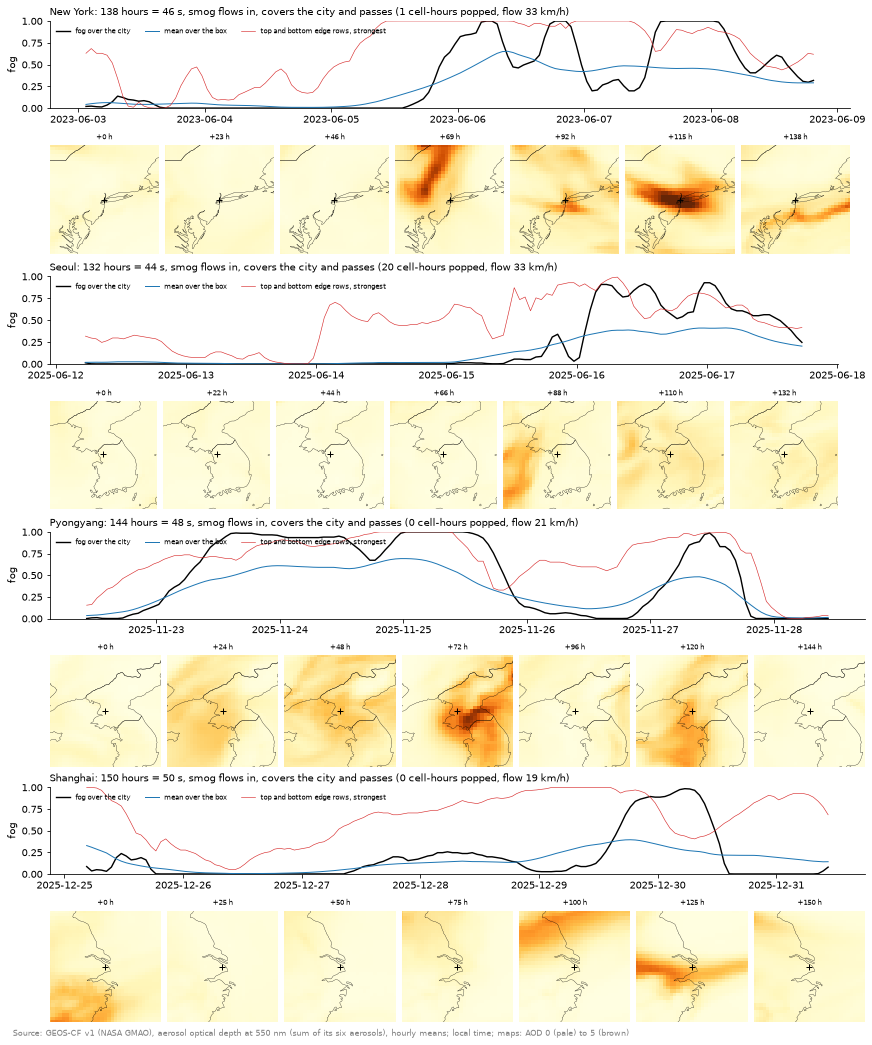

In [9]:
countries = gpd.read_file(download("natural_earth/ne_50m_admin_0_countries.zip",
                                   f"{NATURAL_EARTH_50M}/ne_50m_admin_0_countries.zip"))
SNAPSHOTS = 7
fig = plt.figure(figsize=(12, 3.6 * len(picks)), constrained_layout=True)
grid = fig.add_gridspec(len(picks), 1)
for g, p in zip(grid, picks.itertuples()):
    sub = g.subgridspec(2, SNAPSHOTS, height_ratios=[1, 1.3])
    ax = fig.add_subplot(sub[0, :])
    tz = ZoneInfo(p.tz)
    local = [utc_hour(p.first + h).astimezone(tz).replace(tzinfo=None) for h in range(len(p.haze))]
    ax.plot(local, p.haze, color="k", lw=1.4, label="fog over the city")
    ax.plot(local, p.fog.reshape(len(local), -1).mean(1), color="tab:blue", lw=1, label="mean over the box")
    ax.plot(local, p.fog[:, [0, -1], :].max((1, 2)).clip(0), color="tab:red", lw=0.6, label="top and bottom edge rows, strongest")
    ax.set_ylim(0, 1); ax.set_ylabel("fog")
    ax.set_title(f"{p.city}: {p.hours} hours = {p.seconds:.0f} s, smog flows in, covers the city and passes "
                 f"({p.pop} cell-hours popped, flow {p.flow_kmh:.0f} km/h)", loc="left", fontsize=10)
    ax.legend(fontsize=7, loc="upper left", ncol=3, frameon=False)
    r, k = cell(p.lat, p.lon)
    lats = (r - BOX + np.arange(2 * BOX + 1)) * GRID_DEG - 90
    lons = (k - BOX + np.arange(2 * BOX + 1)) * GRID_DEG - 180
    for col, h in enumerate(np.linspace(0, p.hours, SNAPSHOTS).astype(int)):
        m = fig.add_subplot(sub[1, col])
        m.pcolormesh(lons, lats, p.frames[h], cmap="YlOrBr", vmin=0, vmax=AOD_FULL, shading="nearest")
        countries.boundary.plot(ax=m, color="k", linewidth=0.3)
        m.plot(p.lon, p.lat, "k+", ms=6)
        m.set_xlim(lons[0], lons[-1]); m.set_ylim(lats[0], lats[-1]); m.set_aspect("equal"); m.axis("off")
        m.set_title(f"+{h} h", fontsize=7)
fig.supxlabel(CREDIT + "; local time; maps: AOD 0 (pale) to 5 (brown)", x=0.01, ha="left", fontsize=8, color="gray")
plt.show()

Each song's graph shows the city's fog (black) beside the box's mean (blue) and its top and bottom edge rows (red); the maps below it are seven moments of the song, the smog drifting over the box.

## 6. Track data

Each song becomes one CSV in `data/smog/tracks/`: a row per hour (`time`, in UTC), then each cell's aerosol optical depth at 550 nm to three decimals, south to north and west to east (a column per cell, named `<lat>_<lon>`). `tracks.json` gives the box, the city and the time zone the app shows the clock in. A song plays its hours at 3 hours a second, so its length is its hours divided by 3.

In [10]:
if TRACKS.exists():
    for old in TRACKS.iterdir():
        old.unlink()
TRACKS.mkdir(parents=True, exist_ok=True)
MESSAGE = ("Though small particles typically remain in the atmosphere for only a few days, they can be transported far "
           "away from source regions by large scale weather systems.")

entries, summary = [], []
for p in picks.itertuples():
    r, k = cell(p.lat, p.lon)
    lats = (r - BOX + np.arange(2 * BOX + 1)) * GRID_DEG - 90
    lons = (k - BOX + np.arange(2 * BOX + 1)) * GRID_DEG - 180
    hours = [utc_hour(p.first + h) for h in range(len(p.frames))]
    file = f"{p.city.lower().replace(' ', '_')}_{hours[0]:%Y}.csv"
    table = pd.DataFrame(np.round(p.frames.reshape(len(hours), -1), AOD_DECIMALS),
                         columns=[f"{lat:g}_{lon:g}" for lat in lats for lon in lons])
    table.insert(0, "time", [f"{t:%Y-%m-%dT%H:%MZ}" for t in hours])
    table.to_csv(TRACKS / file, index=False, float_format=f"%.{AOD_DECIMALS}f")
    entries.append({
        "file": file,
        "title": p.city,
        "pages": [{"svsId": 5151, "svsUrl": "https://svs.gsfc.nasa.gov/5151/", "message": MESSAGE}],
        "note": ("Ours: smog blown in from outside the map, over the city and on, picked by the rules of section 5; every hour "
                 f"of it, played at {HOURS_PER_SEC} hours a second ({p.seconds:.0f} s)."),
        "sources": [{
            "source": f"GEOS-CF v1 (NASA GMAO), xgc_tavg_1hr_g1440x721_x1, the sum of {', '.join(AOD_PARTS)}",
            "sourceUrl": "https://gmao.gsfc.nasa.gov/gmao-products/geos-cf/",
            "downloadUrl": f"{OPENDAP}.dods?" + ",".join(
                f"{v}.{v}[{p.first}:{p.first + len(hours) - 1}][{r - BOX}:{r + BOX}][{k - BOX}:{k + BOX}]" for v in AOD_PARTS),
            "version": "v1",
            "doi": "https://doi.org/10.1029/2020MS002413",
            "downloaded": "2026-11-15",
            "license": "NASA data, no restrictions on use",
            "credit": ("Keller, C. A., et al. (2021). Description of the NASA GEOS composition forecast modeling system "
                       "GEOS-CF v1.0. JAMES 13, e2020MS002413."),
            "substitute": ("EIC 5151 shows surface PM2.5 from GEOS-CF v2 (from 2025-08-04); the album plays the same model's "
                           "column AOD (v1 holds every song), as surface PM2.5 empties and refills in place each day."),
        }],
        "city": {"name": p.city, "lat": p.lat, "lon": p.lon},
        "grid": {"south": float(lats[0]), "west": float(lons[0]), "stepDeg": GRID_DEG, "rows": len(lats), "cols": len(lons)},
        "timeZone": p.tz,
        "units": {"<lat>_<lon>": "aerosol optical depth at 550 nm, unitless (hourly mean, the cell centred there)"},
        "timeRange": [table["time"].iloc[0], table["time"].iloc[-1]],
    })
    size = (TRACKS / file).stat().st_size
    assert size < 3e6, (file, size)
    tz = ZoneInfo(p.tz)
    summary.append({"song": p.city, "region": p.region, "file": file,
                    "local": f"{hours[0].astimezone(tz):%Y-%m-%d %H:%M} to {hours[-1].astimezone(tz):%m-%d %H:%M}",
                    "hours": len(hours) - 1, "seconds": p.seconds, "pop": p.pop, "change": round(p.change, 1),
                    "flow_kmh": round(p.flow_kmh, 1),
                    "KB": round(size / 1024)})
(TRACKS / "tracks.json").write_text(json.dumps(entries, indent=2, ensure_ascii=False) + "\n")
pd.DataFrame(summary).set_index("song")

,region,file,local,hours,seconds,pop,change,flow_kmh,KB
song,,,,,,,,,
New York,Northern America,new_york_2023.csv,2023-06-03 01:30 to 06-08 19:30,138,46.0,1,3.5,33.4,901
Seoul,Eastern Asia,seoul_2025.csv,2025-06-12 05:30 to 06-17 17:30,132,44.0,20,2.0,33.4,863
Pyongyang,Eastern Asia,pyongyang_2025.csv,2025-11-22 10:30 to 11-28 10:30,144,48.0,0,3.0,20.7,939
Shanghai,Eastern Asia,shanghai_2025.csv,2025-12-25 04:30 to 12-31 10:30,150,50.0,0,2.2,18.5,978


## 7. Summary

| Item | Value |
| --- | --- |
| EIC page | [5151 Particulate Matter (PM) 2.5](https://svs.gsfc.nasa.gov/5151/) |
| EIC message | Small particles stay in the air for a few days and are carried far from their sources by the weather |
| The rule (ours) | Smog that enters the box from outside, covers the city and leaves, in clear air at both ends, with at most a few cells of fog popping up inside; the most change in the city's pollution level; 132 to 150 hours |
| Cities | New York (2023, the user's choice), Seoul, Pyongyang, Shanghai (2025); three of them in East Asia, as no other region's 2025 air passed |
| Quantity | Aerosol optical depth at 550 nm (GEOS-CF's column), not 5151's surface PM2.5, which blinks out each morning |
| Time | One fixed speed, 3 hours of data a second (6 hours a bar); songs of 50, 48, 46 and 44 s |
| Tracks | The four songs in section 6: every hour of each, the 33 × 33 cells (0.25°, ±4°) around the city |
| What the app does with them | `src/features/tracks/domain/smog.js`: the fog and the playback times; see [docs/albums/smog.md](../docs/albums/smog.md) |